> # Dataset class

In [ ]:
#This is the Dataset class
import numpy as np
import torch
from torch.utils.data import Dataset
import os
from sklearn.model_selection import train_test_split

class SITSData(Dataset):
    def __init__(self, mode='train', transform=None):
        self.patch_list = []
        self.gt_list = []
        self.root = '/root/input/grapes-dataset'
        self.mode = mode
        
        # This is a customary way of loading the dataset. Modify as required.
        for path in os.listdir(self.root):
            cp = os.path.join(self.root, path)  # Full path

            if mode == 'train':
                if path[-1] in ['4']:
                    g = cp+'/'+'2022'+'/'
                    self.getfiles(g,'Grapes')
               
                if path[-1] in ['5']:
                    ng = cp+'/'+'2022'+'/'
                    self.getfiles(ng,'Non Grapes')    

            if mode == 'test':

                if path[-1] in ['2']:          
                    g = cp+'/'+'2022'+'/'
                    self.getfiles(g,'Grapes')
                if path[-1] in ['3']:
                    ng = cp + '/' + '2022' +'/'
                    self.getfiles(ng,'Non Grapes')
    
    # Custom helper function to load the data
    def getfiles(self, path, wanted):
    
        for cls in os.listdir(path):
            cls_path = os.path.join(path, cls)  # Get full path
            
            if not os.path.isdir(cls_path):  # Ensure it's a directory
                continue
    
            if cls == wanted:
                for i,patch in enumerate(os.listdir(cls_path)):
                    # print(cls_path,patch)
                    self.patch_list.append(os.path.join(cls_path, patch))
                    self.gt_list.append(1 if wanted == "Grapes" else 0)  # Assign label based on class

                    if  i == 4892 and self.mode == 'test' and wanted == 'Non Grapes':
                        break

                    if  i == 100 and self.mode == 'train' and wanted == 'Grapes':
                        break

                    if  i == 2000 and self.mode == 'train' and wanted == 'Non Grapes':
                        break
                    
    def __len__(self):
        # Return the number of samples in the training dataset
        return len(self.patch_list)

    # To match the input dim of the AR-STAR
    def reshape_sits_data(self,input_array):
   
        # Step 1: Convert each element from numpy.void to a numpy array of shape (280,)
        parsed_data = np.array(input_array.tolist(), dtype=np.float32)  # Convert all elements to float32

        # Step 2: Reshape from (24, 24, 280) → (24, 24, 28, 10)  [time, bands]
        reshaped_data = parsed_data.reshape(24, 24, 10, 28)
    
        # Step 3: Rearrange to (28, 10, 24, 24)  [final shape]
        return np.transpose(reshaped_data, (3, 2, 0, 1))
    
    def __getitem__(self, idx):
        # Get a sample from the training data
        t = np.load(self.patch_list[idx])
        t = self.reshape_sits_data(t)
        t = t/10000.0
        t = torch.tensor(t, dtype=torch.float32)  # Convert to tensor
        
        # Check gt_list[idx] and create the appropriate label tensor
        if self.gt_list[idx] == 1:
            label = torch.ones((24, 24), dtype=torch.float32)  # Tensor of shape (24,24) with all ones
        else:
            label = torch.zeros((24, 24), dtype=torch.float32)  # Tensor of shape (24,24) with all zeros
    
        return t, label

> # Checking the split of train and test

In [ ]:
from torch.utils.data import DataLoader

# Create an instance of the dataset
dataset = SITSData(mode='train')
print(len(dataset))
# Create a DataLoader to fetch batches of data
batch_size = 16  # Define batch size
shuffle = True   # Shuffle data for training

dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)
# Iterate over the dataloader
x, y = 0 , 0
for batch in dataloader:
    samples, labels = batch  # Unpack batch
    print("Batch Sample Shape:", samples.shape)  # Expected: (batch_size, 28, 10, 24, 24)
    print("Batch Label Shape:", labels.shape)    # Expected: (batch_size, 24, 24)
    x, y= samples[0], labels[0]
    break  # Just show one batch

# print(x[0])

> # Model architecture

# ConvSTAR

In [ ]:
# This is the ConvSTAR classs
import torch
import torch.nn as nn
#import numpy as np
#import torch.nn.functional as F
from torch.nn import init

class ARelu(nn.Module):

    def __init__(self, alpha=0.75, beta=2.0):
        super().__init__()
        self.alpha = nn.Parameter(torch.tensor([alpha]))
        self.beta = nn.Parameter(torch.tensor([beta]))

    def forward(self, input):
        alpha = torch.clamp(self.alpha, min=0.01, max=0.99)
        beta = 1 + torch.sigmoid(self.beta)

        return F.relu(input) * beta - F.relu(-input) * alpha

class ConvSTARCell(nn.Module):
    """
    Convolutional STAR cell
    """

    def __init__(self, input_size, hidden_size, kernel_size):
        super().__init__()
        padding = kernel_size // 2
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.gate = nn.Conv2d(input_size + hidden_size, hidden_size, kernel_size, padding=padding)
        self.update = nn.Conv2d(input_size, hidden_size, kernel_size, padding=padding)
        self.arelu = ARelu()
        
        init.orthogonal(self.update.weight)
        init.orthogonal(self.gate.weight)
        init.constant(self.update.bias, 0.)
        init.constant(self.gate.bias, 1.)

        print('convSTAR cell is constructed with h_dim: ', hidden_size)

    def forward(self, input_, prev_state):

        # get batch and spatial sizes
        batch_size = input_.data.size()[0]
        spatial_size = input_.data.size()[2:]

        # generate empty prev_state, if None is provided
        if prev_state is None:
            state_size = [batch_size, self.hidden_size] + list(spatial_size)
            if torch.cuda.is_available():
                prev_state = Variable(torch.zeros(state_size)).cuda()
            else:
                prev_state = Variable(torch.zeros(state_size))

        # data size is [batch, channel, height, width]
        stacked_inputs = torch.cat([input_, prev_state], dim=1)
        gain = torch.sigmoid( self.gate(stacked_inputs) )
        update = torch.nn.gelu( self.update(input_) )
        new_state = gain * prev_state + (1-gain) * update

        return new_state


class ConvSTAR(nn.Module):

    def __init__(self, input_size, hidden_sizes, kernel_sizes, n_layers):
        '''
        Implements a multi-layer convolutional GRU.
        Preserves spatial dimensions across cells, only altering depth.

        Parameters
        ----------
        input_size : integer. depth dimension of input tensors.
        hidden_sizes : integer or list. depth dimensions of hidden state.
            if integer, the same hidden size is used for all cells.
        kernel_sizes : integer or list. sizes of Conv2d gate kernels.
            if integer, the same kernel size is used for all cells.
        n_layers : integer. number of chained `ConvSTARCell`.
        '''

        super(ConvSTAR, self).__init__()
        
        self.input_size = input_size

        if type(hidden_sizes) != list:
            self.hidden_sizes = [hidden_sizes]*n_layers
        else:
            assert len(hidden_sizes) == n_layers, '`hidden_sizes` must have the same length as n_layers'
            self.hidden_sizes = hidden_sizes
        if type(kernel_sizes) != list:
            self.kernel_sizes = [kernel_sizes]*n_layers
        else:
            assert len(kernel_sizes) == n_layers, '`kernel_sizes` must have the same length as n_layers'
            self.kernel_sizes = kernel_sizes

        self.n_layers = n_layers

        cells = []
        for i in range(self.n_layers):
            if i == 0:
                input_dim = self.input_size
            else:
                input_dim = self.hidden_sizes[i-1]

            cell = ConvSTARCell(input_dim, self.hidden_sizes[i], self.kernel_sizes[i])
            name = 'ConvSTARCell_' + str(i).zfill(2)

            setattr(self, name, cell)
            cells.append(getattr(self, name))

        self.cells = cells

    def forward(self, x, hidden=None):
        '''
        Parameters
        ----------
        x : 4D input tensor. (batch, channels, height, width).
        hidden : list of 4D hidden state representations. (batch, channels, height, width).

        Returns
        -------
        upd_hidden : 5D hidden representation. (layer, batch, channels, height, width).
        '''
        if not hidden:
            hidden = [None]*self.n_layers

        input_ = x

        upd_hidden = []

        for layer_idx in range(self.n_layers):
            cell = self.cells[layer_idx]
            cell_hidden = hidden[layer_idx]
                        
            # pass through layer
            upd_cell_hidden = cell(input_, cell_hidden)
            upd_hidden.append(upd_cell_hidden)
            # update input_ to the last updated hidden layer for next pass
            input_ = upd_cell_hidden

        # retain tensors in list to allow different hidden sizes
        return upd_hidden

# multi stage convSTAR

In [3]:
# This is the ms convSTAR
import torch
import torch.nn as nn
import torch.nn.functional as F

class ConvRNN(nn.Module):
    """A simplified ConvRNN model for pixel-wise binary classification."""
    
    def __init__(self, height=24, width=24, input_dim=10, hidden_dim=64, kernel_size=(3,3), n_layers=6):
        super(ConvRNN, self).__init__()
        self.n_layers = n_layers
        self.hidden_dim = hidden_dim

        # ConvSTAR-based Recurrent Layer
        self.rnn = ConvSTAR(input_size=input_dim,
                            hidden_sizes=hidden_dim,
                            kernel_sizes=kernel_size[0],
                            n_layers=n_layers)

        # Final Conv Layer: Output 1 channel (Binary Classification)
        self.final = nn.Conv2d(hidden_dim, 1, kernel_size=(3, 3), padding=1)

    def forward(self, x, hiddenS=None):
        """
        Input Shape: (batch_size, time_steps, channels, height, width) -> (B, 28, 10, 24, 24)
        """
        # (B, T, C, H, W) → (B, C, T, H, W)
        x = x.permute(0, 2, 1, 3, 4)

        b, c, t, h, w = x.shape

        # Initialize hidden state if not provided
        if hiddenS is None:
            hiddenS = [torch.zeros((b, self.hidden_dim, h, w))] * self.n_layers
            
        if torch.cuda.is_available():
            hiddenS = [h.cuda() for h in hiddenS]

        # Process through the ConvRNN
        for iter in range(t):
            hiddenS = self.rnn(x[:, :, iter, :, :], hiddenS)

        # Get the last hidden state and apply final classification layer
        last = hiddenS[-1]  # Take the last layer's output
        # print(last)
        last = self.final(last)  # (B, 1, H, W)

        return last  # Output is probability (0-1) for each pixel

> # Training AR-STAR

In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torch.utils.tensorboard import SummaryWriter
from sklearn.metrics import confusion_matrix
import numpy as np

BATCH_SIZE = 32
LR = 1e-4
EPOCHS = 30
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_PATH = "/root/grapes/checkpoints/best_model.pth"

train_dataset = SITSData(mode="train")
val_dataset = SITSData(mode='test')
print(len(train_dataset),len(val_dataset))
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=24)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=32)

# -------------------
# MODEL SETUP
# -------------------
model = ConvRNN(input_dim=10, hidden_dim=64).to(DEVICE)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)

start_epoch = 0
# if os.path.exists(CHECKPOINT_PATH):
#     checkpoint = torch.load(CHECKPOINT_PATH)
#     model.load_state_dict(checkpoint["model_state_dict"])
#     optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
#     start_epoch = checkpoint["epoch"] + 1
#     print(f"Resuming training from epoch {start_epoch}...")


writer = SummaryWriter("/root/working/tracking/binary_classification")
best_f1, best_acc = 0.0, 0.0
# -------------------
# 🔹 TRAINING LOOP
# -------------------
for epoch in range(EPOCHS):
    model.train()  # Enable training mode
    train_loss = 0.0
    print(f"Epoch {epoch+1}\n")
    for i,batch in enumerate(train_loader):
        inputs, labels = batch
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE).unsqueeze(1)  # Reshape labels to (batch, 1, 24, 24)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        train_loss += loss.item()
    
    #  VALIDATION LOOP
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        running_cm = np.zeros((2, 2)) 
        for j,batch in enumerate(val_loader):
            inputs, labels = batch
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE).unsqueeze(1)
            outputs = model(inputs)
            # print(torch.unique(labels))
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            probs = torch.sigmoid(outputs)

            # Convert probabilities to binary predictions
            preds = (probs > 0.5).float().cpu().numpy().flatten()
            labels = labels.cpu().numpy().flatten()
            running_cm += confusion_matrix(labels,preds,labels=[0,1])
    print(running_cm)
    tn, fp, fn, tp = running_cm.ravel()
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    # Average losses
    train_loss /= i
    val_loss /= j

    # Print progress
    print(f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")
    print(f"Accuracy: {accuracy:.4f},'\n', Precision: {precision:.4f}, '\n',Recall: {recall:.4f}, '\n',F1-Score: {f1:.4f}")

    # Log to TensorBoard
    writer.add_scalar("Loss/Train", train_loss, epoch)
    writer.add_scalar("Loss/Validation", val_loss, epoch)
    writer.add_scalar("Metrics/Accuracy", accuracy, epoch)
    writer.add_scalar("Metrics/Precision", precision, epoch)
    writer.add_scalar("Metrics/Recall", recall, epoch)
    writer.add_scalar("Metrics/F1-Score", f1, epoch)

    # if best_f1 < f1 or best_acc < accuracy:
    #     # Save checkpoint
    #     torch.save({
    #         "epoch": epoch,
    #         "model_state_dict": model.state_dict(),
    #         "optimizer_state_dict": optimizer.state_dict(),
    #     }, CHECKPOINT_PATH)

# Close TensorBoard writer
# writer.close()

print("Training complete! Run `tensorboard --logdir=runs` to visualize.")


> # Testing

In [ ]:
import pickle

# File paths
pkl_file1 = "/root/input/grapes-test-dataset/drive-download-20250220T081227Z-001/Sample_point_list_grape.pkl"
pkl_file2 = "/root/input/grapes-test-dataset/drive-download-20250220T081227Z-001/Sample_point_list_notgrape.pkl"

# Load first pickle file
with open(pkl_file1, "rb") as f:
    data1 = pickle.load(f)

# Load second pickle file
with open(pkl_file2, "rb") as f:
    data2 = pickle.load(f)

print(data1[0])
data = data1+data2
print(len(data))

{'geodesic': False, 'type': 'Point', 'coordinates': [-119.924181625843, 36.55215083502143]}
40000


In [ ]:
# This class is similar to that of SITSData class but is used explicitly for testing.
import numpy as np
import torch
from torch.utils.data import Dataset
import os

class TestSITSData(Dataset):
    def __init__(self, mode='train', transform=None):
        self.patch_list = []
        self.gt_list = [1] * 20000 + [0] * 20000
        self.coords = data
        self.root1 = '/root/input/grapes-test-dataset/'
        self.root2 = '/root/input/non-grapes-dataset/'

        self.getfiles(self.root1, cls='Grapes')
        self.getfiles(self.root2, cls='Non-Grapes')
        gp = [p for p in self.patch_list if 'TestGrape' in p]
        ngp = [p for p in self.patch_list if 'TestNotGrape' in p]
        
        gp.sort(key=lambda x: int(x[-9:-4]))
        ngp.sort(key=lambda x: int(x[-9:-4]))
        self.patch_list = gp + ngp
        # print(self.patch_list[:5],self.patch_list[-5:], len(self.gt_list))
        
    def getfiles(self, path, cls=''):
        for d in os.listdir(path):
            if d.startswith('drive'):
                continue

            cls_path = path + d + '/' + ('TestGrape' if cls == 'Grapes' else 'TestNotGrape') + '/'
            for patch in os.listdir(cls_path):
                self.patch_list.append(os.path.join(cls_path, patch))

    def __len__(self):
        return len(self.patch_list)

    def reshape_sits_data(self, input_array):
        parsed_data = np.array(input_array.tolist(), dtype=np.float32)  # Convert all elements to float32
        reshaped_data = parsed_data.reshape(24, 24, 10, 28)
        return np.transpose(reshaped_data, (3, 2, 0, 1))

    def __getitem__(self, idx):
        t = np.load(self.patch_list[idx])
        t = self.reshape_sits_data(t) / 10000.0
        t = torch.tensor(t, dtype=torch.float32)  # Convert to tensor
        
        label = torch.ones((24, 24), dtype=torch.float32) if self.gt_list[idx] == 1 else torch.zeros((24, 24), dtype=torch.float32)
        coords = self.coords[idx]
        return t, label, coords['coordinates']


In [5]:
from torch.utils.data import DataLoader

# Create an instance of the dataset
dataset = TestSITSData(mode='test')
# print(len(dataset))
# Create a DataLoader to fetch batches of data
batch_size = 16  # Define batch size
shuffle = True   # Shuffle data for training

dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)
# Iterate over the dataloader
x, y = 0 , 0
for batch in dataloader:
    samples, labels, coords = batch  # Unpack batch
    print("Batch Sample Shape:", samples.shape)  # Expected: (batch_size, 28, 10, 24, 24)
    print("Batch Label Shape:", labels.shape)    # Expected: (batch_size, 24, 24)
    print("Batch coords Shape:", len(coords))    # Expected: (batch_size, 24, 24)
    print(coords[0][0],coords[0][1])
    x, y = samples[0], labels[0]
    break  # Just show one batch

# print(x[0])

Batch Sample Shape: torch.Size([16, 28, 10, 24, 24])
Batch Label Shape: torch.Size([16, 24, 24])
Batch coords Shape: 2
tensor(-119.9174, dtype=torch.float64) tensor(-119.8331, dtype=torch.float64)


> # Testing AR-STAR

In [ ]:
import torch
import numpy as np
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix

# -------------------
# CONFIGURATIONS
# -------------------
BATCH_SIZE = 32
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_PATH = "/root/working/grapes/tanh/best_model.pth"

# Load the test dataset
test_dataset = SITSData()
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=16)
print(len(test_dataset))
# Load the model
model = ConvRNN(input_dim=10, hidden_dim=64).to(DEVICE)
model = model.to(DEVICE)
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
print(checkpoint.keys())
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()  # Set model to evaluation mode

running_cm = np.zeros((2, 2),dtype='int')  # For binary classification
test_loss = 0.0
criterion = torch.nn.BCEWithLogitsLoss()  # Use the same loss function as training

with torch.no_grad():
    for batch in test_loader:
        inputs, labels = batch
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE).unsqueeze(1)  # Shape (batch, 1, 24, 24)

        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        test_loss += loss.item()
        # print(outputs[0])
        # Convert logits to probabilities
        probs = torch.sigmoid(outputs)

        # Convert probabilities to binary predictions
        preds = (probs > 0.5).float().cpu().numpy().flatten()
        labels = labels.cpu().numpy().flatten()

        # Update confusion matrix
        running_cm += confusion_matrix(labels, preds, labels=[0, 1])
        # print(running_cm)

tn, fp, fn, tp = running_cm.ravel()
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

# Average test loss
test_loss /= len(test_loader)
np.save('/root/working/confusion_matrix.npy',running_cm)
# Print results
print(f"Test Loss: {test_loss:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

print("Testing complete!")

40000 40000
40000
convSTAR cell is constructed with h_dim:  64
convSTAR cell is constructed with h_dim:  64
convSTAR cell is constructed with h_dim:  64
convSTAR cell is constructed with h_dim:  64
convSTAR cell is constructed with h_dim:  64
convSTAR cell is constructed with h_dim:  64
dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict'])


/tmp/ipykernel_34/196787282.py:35: UserWarning: nn.init.orthogonal is now deprecated in favor of nn.init.orthogonal_.
  init.orthogonal(self.update.weight)
/tmp/ipykernel_34/196787282.py:36: UserWarning: nn.init.orthogonal is now deprecated in favor of nn.init.orthogonal_.
  init.orthogonal(self.gate.weight)
/tmp/ipykernel_34/196787282.py:37: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(self.update.bias, 0.)
/tmp/ipykernel_34/196787282.py:38: UserWarning: nn.init.constant is now deprecated in favor of nn.init.constant_.
  init.constant(self.gate.bias, 1.)


Test Loss: 0.3874
Accuracy: 0.8390
Precision: 0.7975
Recall: 0.9089
F1-Score: 0.8495
Testing complete!


[[16243.30902778  3756.69097222]
 [ 2512.43923611 17487.56076389]]
[[16243  3757]
 [ 2512 17488]]


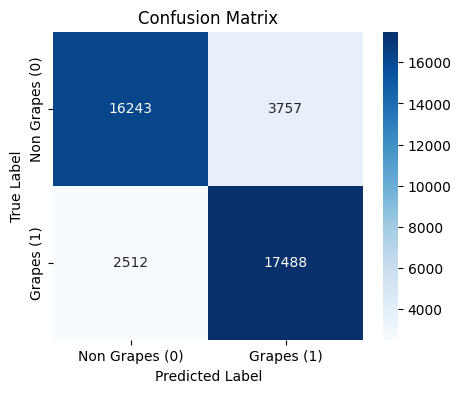

Saved as /kaggle/working/arelu_confusion_matrix.pdf


In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load the 2x2 matrix from a .npy file
matrix = np.load("/kaggle/working/confusion_matrix.npy")
matrix /= 576
print(matrix)
matrix = np.round(matrix).astype(int)
print(matrix)

# Define class labels
class_labels = ["Non Grapes (0)", "Grapes (1)"]

# Create a heatmap
plt.figure(figsize=(5, 4))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", xticklabels=class_labels, yticklabels=class_labels)

# Add axis labels
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")

# Save the figure as a PDF
pdf_filename = "/kaggle/working/arelu_confusion_matrix.pdf"
plt.savefig(pdf_filename, format="pdf", bbox_inches="tight")

# Show the plot (optional)
plt.show()

print(f"Saved as {pdf_filename}")


In [ ]:
import numpy as np

def reconstruct_confusion_matrix(precision, recall, accuracy, f1_score, total_samples):
    # Step 1: Solve for TP and FN using recall
    beta = (2 * precision * recall) / f1_score  # F1-score equation rearranged
    TP_plus_FN = recall * total_samples  # Total positive samples (assumed from recall definition)
    TP = beta * TP_plus_FN / (1 + beta)  # Solving TP using F1 equation
    FN = TP_plus_FN - TP  # FN from TP + FN

    # Step 2: Solve for FP using precision
    FP = TP * (1 / precision - 1)

    # Step 3: Solve for TN using accuracy
    TN = total_samples - (TP + FP + FN)

    # Round values to nearest integers
    TN, FP, FN, TP = map(lambda x: int(round(x)), [TN, FP, FN, TP])

    # Construct confusion matrix
    cm = np.array([[TN//576, FP//576], [FN//576, TP//576]])
    return cm

# Example values (modify based on actual data)
precision = 0.9362
recall = 0.9273
accuracy = 0.922
f1_score = 0.9317
total_samples = 40000  # Given

conf_matrix = reconstruct_confusion_matrix(precision, recall, accuracy, f1_score, total_samples)
print("Reconstructed Confusion Matrix:\n", conf_matrix)
